# Minor Project: Obesity Level Classification Using XGBoost

Name: Akshat Shankar Bidwai

**Project type:** Supervised machine-learning classification | **Method:** XGBoost with hyperparameter tuning

## 1. Problem statement and objective

The goal is to classify an individual's recorded obesity level from the lifestyle, eating-habit, family-history, and physical-condition features available in the dataset. The target column is `NObeyesdad`, which contains seven classes: `Insufficient_Weight`, `Normal_Weight`, `Overweight_Level_I`, `Overweight_Level_II`, `Obesity_Type_I`, `Obesity_Type_II`, and `Obesity_Type_III`.

This is a **multiclass classification** exercise intended to study patterns in the dataset. The output is not a clinical diagnosis and should not be used as a substitute for professional medical assessment.

## 2. Dataset source and description

**Kaggle dataset:** [Obesity Levels](https://www.kaggle.com/datasets/fatemehmehrparvar/obesity-levels)

The supplied CSV contains **2,111 rows and 17 columns before cleaning**: 16 predictor attributes and the `NObeyesdad` target. Features cover age, gender, height, weight, family history of overweight, food consumption habits, water intake, physical activity, technology use, smoking, alcohol consumption, and transportation mode. The analysis below uses the CSV file loaded in the next cell.

> Reproducibility note: the existing code reads `/content/ObesityDataSet_raw_and_data_sinthetic.csv`. Place the dataset CSV at that path, or adjust only the file path in your working copy if your environment stores it elsewhere.

## 3. Notebook roadmap

The notebook checks structure and data quality, explores distributions and relationships, encodes categorical variables, splits the data into training and testing sets, applies SMOTE to training data, tunes XGBoost with stratified cross-validation, and evaluates the selected model using classification metrics and a confusion matrix.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## 4. Load and inspect the data

The following cells load the CSV and inspect the first records and schema. `df.info()` summarizes row counts, non-null values, and data types; the summary and frequency tables then help establish sensible cleaning and modelling steps.

In [2]:
dft = pd.read_csv("/content/ObesityDataSet_raw_and_data_sinthetic.csv")
df = dft.copy()
df.head()

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   object 
 12  FAF                             21

### Data quality checks: duplicates and missing values

Duplicate rows are counted before removal, and the duplicate count is checked again afterwards. Missing values are inspected column by column. These checks support the data-cleaning decisions rather than assuming the source data is already clean.

In [4]:
df.duplicated().sum()

np.int64(24)

In [5]:
df.drop_duplicates(inplace = True)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [8]:
df.isna().sum()

,0
Age,0
Gender,0
Height,0
Weight,0
CALC,0
FAVC,0
FCVC,0
NCP,0
SCC,0
SMOKE,0


**Observed dataset structure:** the loaded file has 2,111 rows and 17 columns. The saved `df.isna().sum()` output reports zero missing values in every column. The duplicate check reports 24 duplicate rows; the notebook removes them, leaving 2,087 rows for subsequent exploration. No missing-value imputation is needed for this loaded file.

In [9]:
df["NObeyesdad"].value_counts()

,count
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_II,290
Normal_Weight,282
Overweight_Level_I,276
Insufficient_Weight,267


In [10]:
df["Gender"].value_counts()

,count
Gender,
Male,1052
Female,1035


In [11]:
df["MTRANS"].value_counts()

,count
MTRANS,
Public_Transportation,1558
Automobile,456
Walking,55
Motorbike,11
Bike,7


In [12]:
df["SMOKE"].value_counts()

,count
SMOKE,
no,2043
yes,44


## 5. Outlier review

The boxplot provides a visual scan of numeric columns, and the interquartile-range (IQR) calculation counts observations outside the usual 1.5 × IQR bounds. **These cells identify candidate outliers; they do not delete or cap them.** Keeping that distinction explicit avoids implying a cleaning action that the code does not perform.

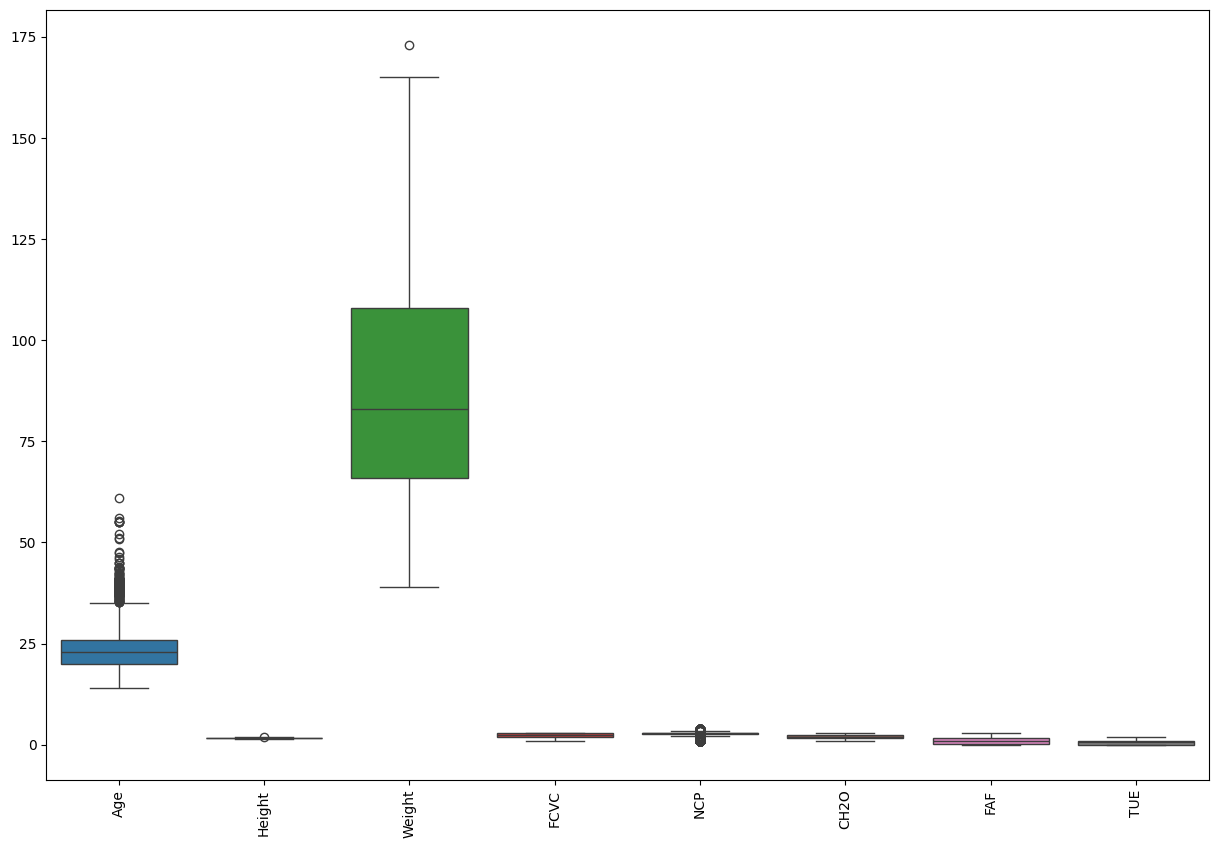

In [13]:
#Outlier Treatment:
plt.figure(figsize = (15,10))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation=90)
plt.show()

In [14]:
from numpy._core.defchararray import lower
for col in df.select_dtypes(include = 'number').columns:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

  print(f"Outliers in {col}:{len(outliers)}")

Outliers in Age:167
Outliers in Height:1
Outliers in Weight:1
Outliers in FCVC:0
Outliers in NCP:577
Outliers in CH2O:0
Outliers in FAF:0
Outliers in TUE:0


## 6. Exploratory data analysis (EDA)

The univariate charts below describe the target-class distribution, gender, age, family history, food choices, meal-between-meal behaviour, smoking, and weight. The bivariate charts compare selected lifestyle features across target classes. The comments that follow record observable patterns, not causal conclusions.

In [15]:
#Univariate Analysis:
print(df["NObeyesdad"].value_counts(normalize = True)*100)

NObeyesdad
Obesity_Type_I         16.818400
Obesity_Type_III       15.524677
Obesity_Type_II        14.230954
Overweight_Level_II    13.895544
Normal_Weight          13.512218
Overweight_Level_I     13.224724
Insufficient_Weight    12.793483
Name: proportion, dtype: float64


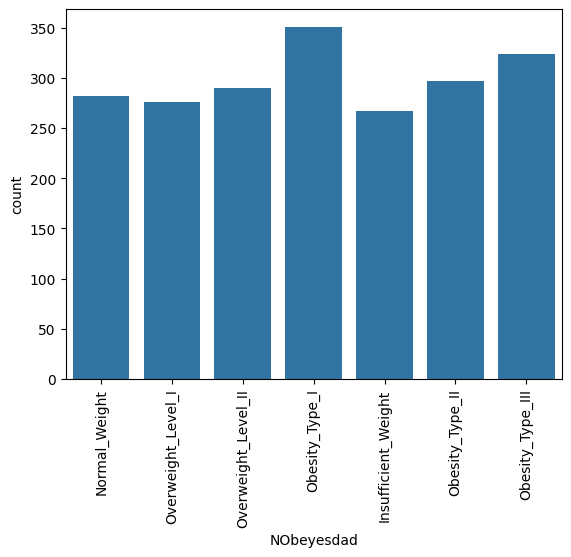

In [16]:
sns.countplot(data=df, x="NObeyesdad")
plt.xticks(rotation = 90)
plt.show()

**Observation - target classes:** after duplicate removal, the seven target classes have fairly similar counts. `Obesity_Type_I` is the largest class (351 records; about 16.8%) and `Insufficient_Weight` is the smallest (267; about 12.8%). This is not a severely imbalanced target distribution, although class-wise evaluation is still useful.

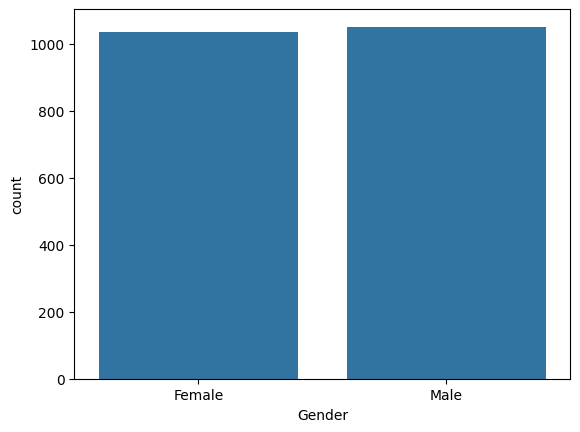

In [17]:
sns.countplot(data = df, x= "Gender")
plt.show()

**Observation - gender:** the data is nearly balanced by gender: 1,052 male and 1,035 female records after duplicate removal. The count chart therefore does not show a major gender-count imbalance in this dataset.

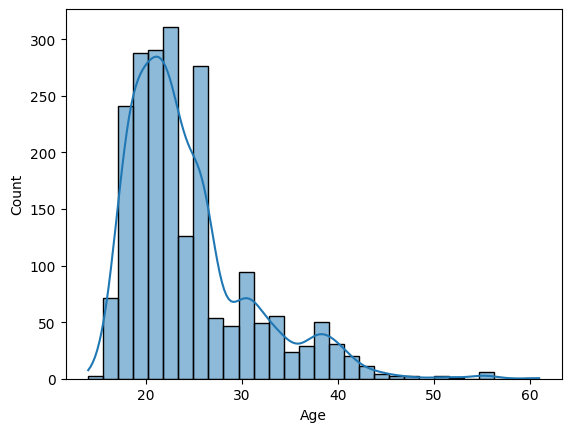

In [18]:
sns.histplot(df['Age'], kde = True, bins=30)
plt.show()

**Observation - age:** age ranges from 14 to 61 years in the cleaned data. The mean age is about 24.35 years and the median is about 22.85 years, so the sample is concentrated toward younger participants with a longer upper-age tail. The dataset may not represent every age group equally.

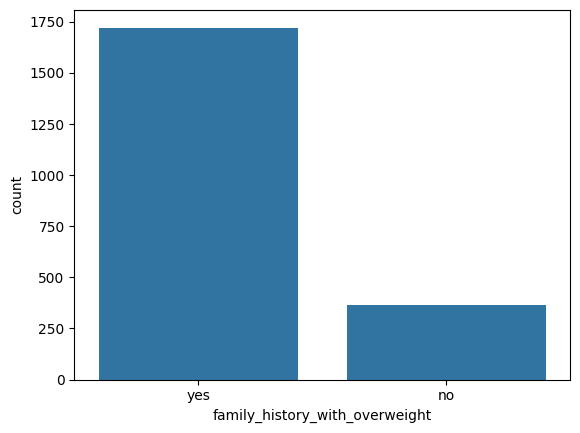

In [19]:
sns.countplot(data = df, x= "family_history_with_overweight")
plt.show()

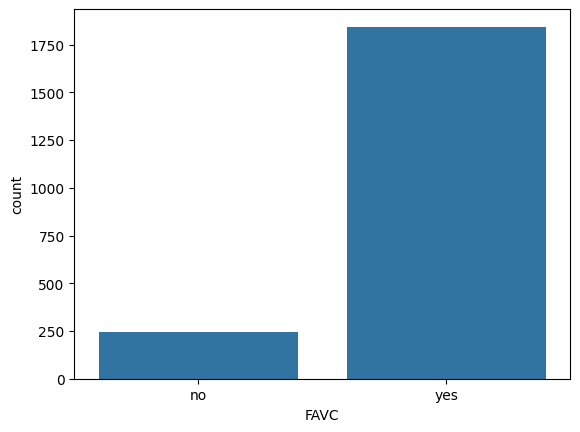

In [20]:
sns.countplot(data = df, x= "FAVC")
plt.show()

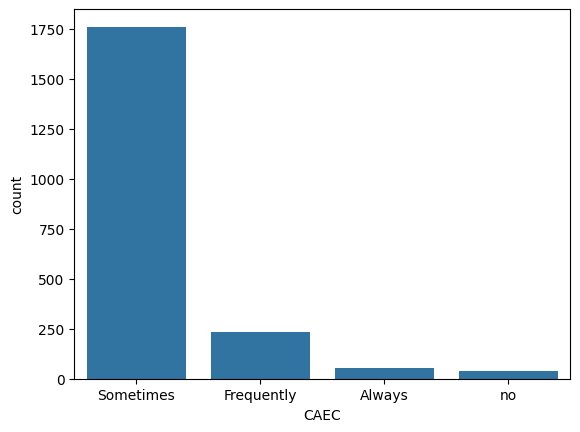

In [21]:
sns.countplot(data = df, x= "CAEC")
plt.show()

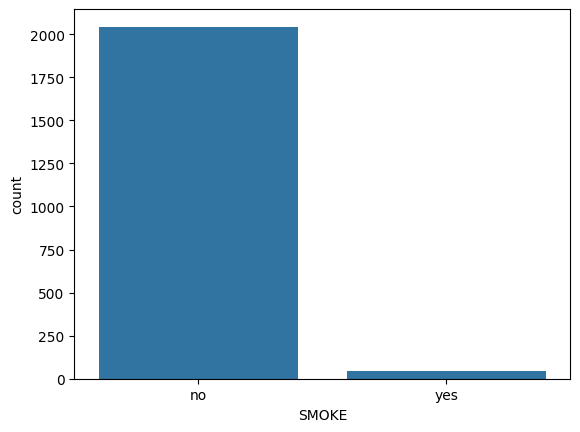

In [22]:
sns.countplot(data = df, x= "SMOKE")
plt.show()

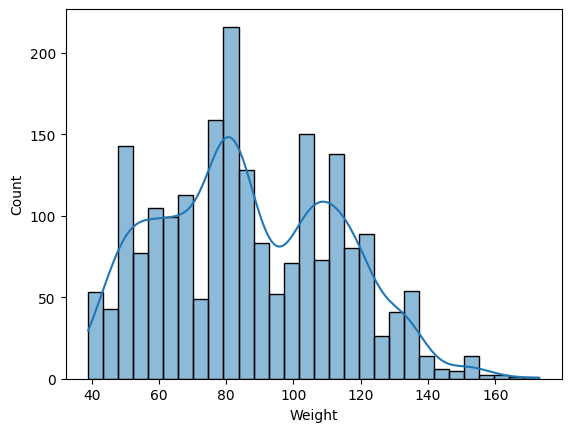

In [23]:
sns.histplot(df['Weight'], kde = True, bins=30)
plt.show()

**Observation - weight:** weight ranges from 39 to 173 kg, with a mean of about 86.86 kg and a median of about 83.10 kg. The histogram helps show spread and skew, but weight alone should not be interpreted as a complete measure of health.

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Normal_Weight'),
  Text(1, 0, 'Overweight_Level_I'),
  Text(2, 0, 'Overweight_Level_II'),
  Text(3, 0, 'Obesity_Type_I'),
  Text(4, 0, 'Insufficient_Weight'),
  Text(5, 0, 'Obesity_Type_II'),
  Text(6, 0, 'Obesity_Type_III')])

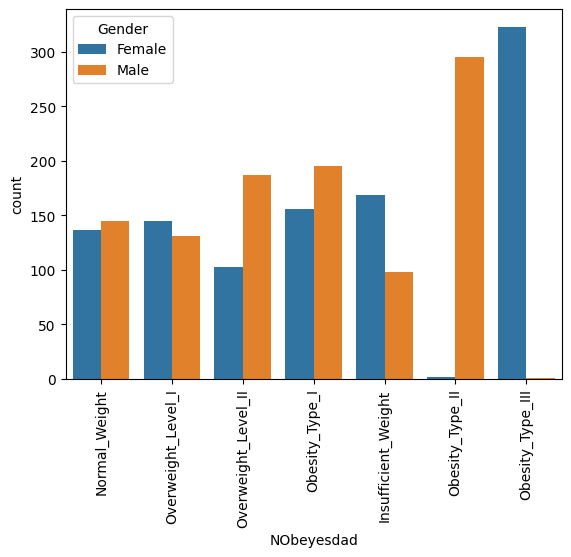

In [24]:
# Bivariate Analysis:
sns.countplot(data=df, x="NObeyesdad", hue="Gender")
plt.xticks(rotation = 90)

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Normal_Weight'),
  Text(1, 0, 'Overweight_Level_I'),
  Text(2, 0, 'Overweight_Level_II'),
  Text(3, 0, 'Obesity_Type_I'),
  Text(4, 0, 'Insufficient_Weight'),
  Text(5, 0, 'Obesity_Type_II'),
  Text(6, 0, 'Obesity_Type_III')])

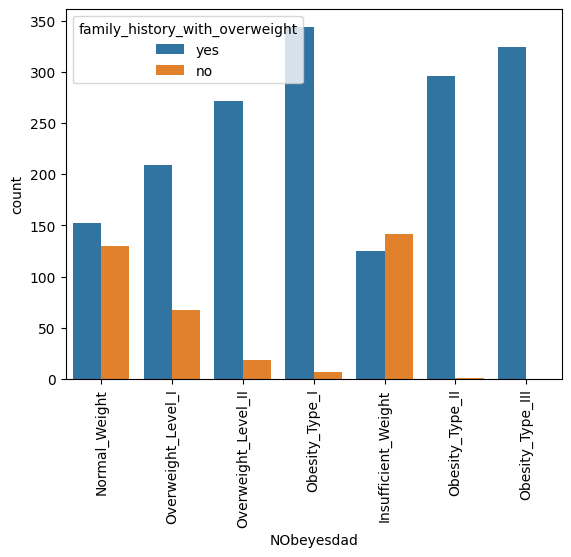

In [25]:
sns.countplot(data=df, x="NObeyesdad", hue="family_history_with_overweight")
plt.xticks(rotation = 90)

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Normal_Weight'),
  Text(1, 0, 'Overweight_Level_I'),
  Text(2, 0, 'Overweight_Level_II'),
  Text(3, 0, 'Obesity_Type_I'),
  Text(4, 0, 'Insufficient_Weight'),
  Text(5, 0, 'Obesity_Type_II'),
  Text(6, 0, 'Obesity_Type_III')])

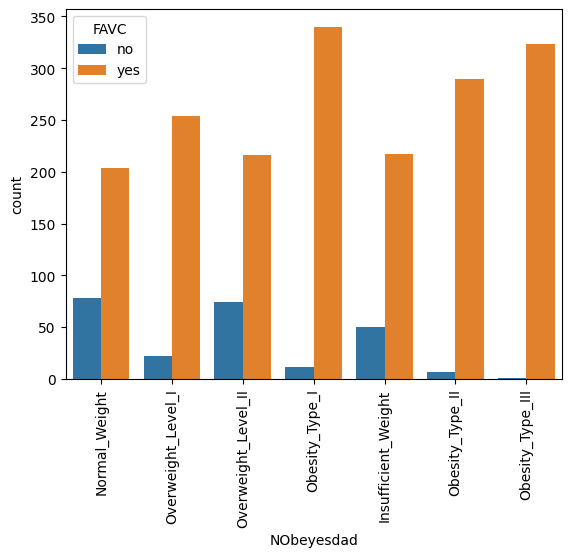

In [26]:
sns.countplot(data=df, x="NObeyesdad", hue="FAVC")
plt.xticks(rotation = 90)

**Bivariate interpretation:** charts split by family history and frequent high-calorie food consumption allow the class counts to be compared across groups. They are descriptive comparisons only; differences in the bars do not prove that a factor causes an obesity category.

## 7. Feature preparation and correlation

Before modelling, the notebook maps the binary `yes`/`no` fields `SMOKE`, `FAVC`, and `family_history_with_overweight` to numeric values. The numeric correlation heatmap summarizes linear associations among the numeric columns at this stage. Correlation is not causation, and weak pairwise correlation does not necessarily mean a feature is uninformative for a nonlinear model.

In [27]:
df['SMOKE'] = df['SMOKE'].map({'yes': 1, 'no': 0}).astype(float)
df['FAVC'] = df['FAVC'].map({'yes': 1, 'no': 0}).astype(float)
df['family_history_with_overweight'] = df['family_history_with_overweight'].map({'yes': 1, 'no': 0}).astype(float)

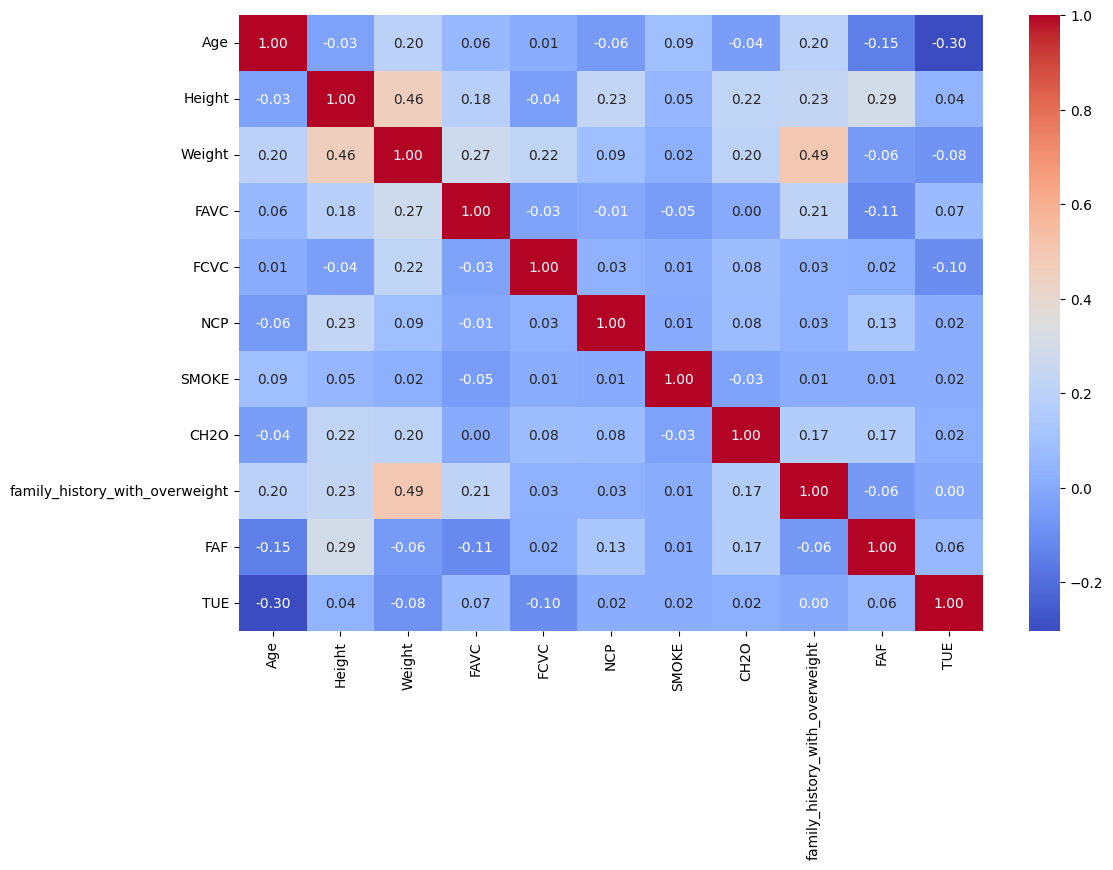

In [28]:
# Multi variate

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

### Encoding categorical predictors

The existing code applies one-hot encoding to `Gender`, `CAEC`, `SCC`, `CALC`, and `MTRANS` with `drop_first=True`, then converts boolean indicator columns to numeric values. These transformations make categorical predictors usable by XGBoost. The target `NObeyesdad` is kept separate and encoded with `LabelEncoder` in the train-test split section.

In [29]:
categorical_cols = ["Gender", "CAEC", "SCC", "CALC", "MTRANS"]
df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

In [30]:
bool_cols = df.select_dtypes(include='bool').columns

df[bool_cols] = df[bool_cols].astype(float)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2087 entries, 0 to 2110
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2087 non-null   float64
 1   Height                          2087 non-null   float64
 2   Weight                          2087 non-null   float64
 3   FAVC                            2087 non-null   float64
 4   FCVC                            2087 non-null   float64
 5   NCP                             2087 non-null   float64
 6   SMOKE                           2087 non-null   float64
 7   CH2O                            2087 non-null   float64
 8   family_history_with_overweight  2087 non-null   float64
 9   FAF                             2087 non-null   float64
 10  TUE                             2087 non-null   float64
 11  NObeyesdad                      2087 non-null   object 
 12  Gender_Male                     2087 no

## 8. Train-test split

The code reserves 20% of the records for final testing and uses `stratify=y_encoded` to preserve approximately the same class proportions in train and test subsets. `random_state=42` makes the split reproducible. The test set is intended to remain untouched during hyperparameter selection and model fitting.

In [32]:
# Train-test split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop("NObeyesdad", axis=1)
y = df["NObeyesdad"]

# XGBoost requires class labels encoded as integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)

Shape of X_train: (1669, 23)
Shape of X_test: (418, 23)


## 9. Handle class counts in training data with SMOTE

SMOTE creates synthetic minority-class examples from the **training subset only**. The saved notebook prints each target-class count before and after resampling so the balancing effect can be checked. The untouched test set is not resampled. During cross-validation, SMOTE is applied afresh only to each fold's training partition.

In [33]:
# Smote Technique
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [34]:
# Check class distribution before and after SMOTE
print("Before SMOTE:")
print(pd.Series(label_encoder.inverse_transform(np.asarray(y_train, dtype=int))).value_counts().sort_index())

print("\nAfter SMOTE:")
print(pd.Series(label_encoder.inverse_transform(np.asarray(y_train_smote, dtype=int))).value_counts().sort_index())

Before SMOTE:
Insufficient_Weight    214
Normal_Weight          225
Obesity_Type_I         281
Obesity_Type_II        237
Obesity_Type_III       259
Overweight_Level_I     221
Overweight_Level_II    232
Name: count, dtype: int64

After SMOTE:
Insufficient_Weight    281
Normal_Weight          281
Obesity_Type_I         281
Obesity_Type_II        281
Obesity_Type_III       281
Overweight_Level_I     281
Overweight_Level_II    281
Name: count, dtype: int64


## 10. XGBoost model and hyperparameter tuning

XGBoost is used as a gradient-boosted decision-tree classifier for the seven target classes. The tuning code samples 12 combinations from the specified parameter ranges and evaluates them with stratified 3-fold cross-validation. Macro F1-score is the selection metric because it gives each class equal weight; the best mean cross-validation macro F1 determines the selected parameter set. This is implemented directly without a pipeline.

In [35]:
!pip install xgboost

## XGBoost Hyperparameter Tuning

Tune XGBoost using stratified 3-fold cross-validation and macro F1-score. SMOTE is applied separately to each fold's training partition, not to that fold's validation partition. This avoids using synthetic samples derived from validation-fold observations. No pipeline is used.

In [36]:
from sklearn.model_selection import StratifiedKFold, ParameterSampler
from sklearn.metrics import f1_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# Hyperparameter combinations to sample
param_distributions = {
    "n_estimators": [100, 150, 200, 250],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.03, 0.05, 0.1, 0.15],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3]
}

# Search 12 randomly selected combinations with 3-fold CV
sampled_params = list(ParameterSampler(
    param_distributions,
    n_iter=12,
    random_state=42
))

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
y_train_array = np.asarray(y_train, dtype=int)
cv_results = []

for candidate_number, params in enumerate(sampled_params, start=1):
    fold_scores = []

    for fold_number, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train_array), start=1):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_valid = X_train.iloc[valid_idx]
        y_fold_train = y_train_array[train_idx]
        y_fold_valid = y_train_array[valid_idx]

        # Apply SMOTE only to this fold's training data
        fold_smote = SMOTE(random_state=42)
        X_fold_train_smote, y_fold_train_smote = fold_smote.fit_resample(
            X_fold_train, y_fold_train
        )

        fold_model = XGBClassifier(
            objective="multi:softprob",
            num_class=len(label_encoder.classes_),
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1,
            tree_method="hist",
            **params
        )
        fold_model.fit(X_fold_train_smote, y_fold_train_smote)
        fold_pred = fold_model.predict(X_fold_valid)
        fold_scores.append(f1_score(y_fold_valid, fold_pred, average="macro", zero_division=0))

    mean_cv_f1 = float(np.mean(fold_scores))
    cv_results.append({
        "candidate": candidate_number,
        "mean_cv_macro_f1": mean_cv_f1,
        "std_cv_macro_f1": float(np.std(fold_scores)),
        **params
    })
    print(f"Candidate {candidate_number}/{len(sampled_params)} | Mean CV macro F1: {mean_cv_f1:.4f} | Params: {params}")

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="mean_cv_macro_f1", ascending=False
).reset_index(drop=True)

best_params = {
    key: cv_results_df.loc[0, key]
    for key in param_distributions.keys()
}

print("\nBest hyperparameters:")
print(best_params)
print(f"Best mean CV macro F1: {cv_results_df.loc[0, 'mean_cv_macro_f1']:.4f}")

display(cv_results_df.head(5))

Candidate 1/12 | Mean CV macro F1: 0.9420 | Params: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.8}
Candidate 2/12 | Mean CV macro F1: 0.9380 | Params: {'subsample': 0.9, 'n_estimators': 150, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}
Candidate 3/12 | Mean CV macro F1: 0.9435 | Params: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0.3, 'colsample_bytree': 0.9}
Candidate 4/12 | Mean CV macro F1: 0.9413 | Params: {'subsample': 0.9, 'n_estimators': 250, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.15, 'gamma': 0, 'colsample_bytree': 0.8}
Candidate 5/12 | Mean CV macro F1: 0.9416 | Params: {'subsample': 0.9, 'n_estimators': 250, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}
Candidate 6/12 | Mean CV macro F1: 0.9393

,candidate,mean_cv_macro_f1,std_cv_macro_f1,subsample,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree
0,9,0.944582,0.005665,0.9,250,3,6,0.03,0.0,0.8
1,3,0.943507,0.010801,1.0,200,5,4,0.05,0.3,0.9
2,1,0.941965,0.007024,1.0,200,5,6,0.05,0.1,0.8
3,5,0.941613,0.010910,0.9,250,5,5,0.10,0.1,1.0
4,4,0.941349,0.013701,0.9,250,5,3,0.15,0.0,0.8


## Train the Best XGBoost Model and Evaluate on the Test Set

The selected parameters are used to fit one final model on the complete SMOTE-resampled training set. The test set remains untouched until this final evaluation.

### Fit the selected model

After tuning, the selected hyperparameters are used to train one final XGBoost model on the full SMOTE-resampled training subset. The test subset is not used for fitting.

In [37]:
best_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    **best_params
)

best_model.fit(X_train_smote, y_train_smote)
print("Best XGBoost model trained successfully.")

Best XGBoost model trained successfully.


## Classification Metrics

## 11. Classification evaluation

The evaluation code predicts labels and class probabilities for the original, untouched test set. Interpret the measures as follows:

- **Accuracy:** fraction of test records classified correctly overall.
- **Precision:** proportion of predicted members of a class that are correct; low precision means more false positives for that class.
- **Recall:** proportion of actual members of a class that are recovered; low recall means more missed cases.
- **F1-score:** harmonic mean of precision and recall. Macro averages give each class equal weight, while weighted averages account for class support.
- **Weighted one-vs-rest ROC-AUC:** summarizes how well predicted probabilities rank each class against the others.

The classification report gives class-wise metrics, and the confusion matrix shows which classes are most often confused. Numeric model scores will appear when the model and evaluation cells are executed in the target environment.

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predictions on the untouched test set
y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro Precision:", round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Macro Recall:", round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Macro F1-score:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Weighted Precision:", round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Multiclass ROC-AUC (weighted, OVR):", round(
    roc_auc_score(y_test, y_pred_proba, multi_class="ovr", average="weighted"), 4
))

Test Accuracy: 0.9545
Macro Precision: 0.9528
Macro Recall: 0.9536
Macro F1-score: 0.9531
Weighted Precision: 0.9548
Weighted Recall: 0.9545
Weighted F1-score: 0.9545

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      1.00      0.99        53
      Normal_Weight       0.90      0.93      0.91        57
     Obesity_Type_I       0.99      0.96      0.97        70
    Obesity_Type_II       0.98      1.00      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.91      0.87      0.89        55
Overweight_Level_II       0.92      0.93      0.92        58

           accuracy                           0.95       418
          macro avg       0.95      0.95      0.95       418
       weighted avg       0.95      0.95      0.95       418

Multiclass ROC-AUC (weighted, OVR): 0.9984


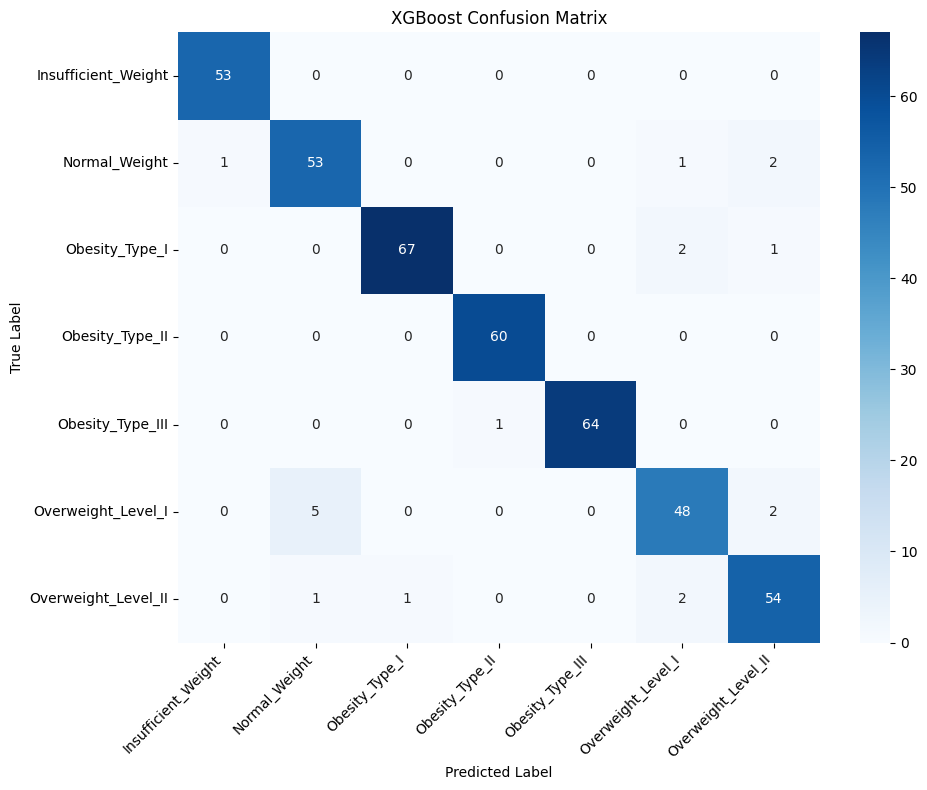

In [39]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("XGBoost Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Conclusion, limitations, and future work

This project builds an end-to-end multiclass classification workflow, from data quality checks and EDA to encoding, train-test splitting, training-only SMOTE, cross-validated XGBoost tuning, and test-set evaluation. The exploratory outputs show no missing values and a reasonably distributed seven-class target after duplicate removal.

**Limitations:** the dataset has 2,087 records after cleaning and may not represent all populations or real-world settings. Height and weight are predictors of a label related to obesity level, so model performance may partly reflect anthropometric information rather than lifestyle alone. The results are predictive associations, not causal evidence or a medical diagnosis. The current notebook's outlier cells flag unusual values but do not remove them.

**Possible improvements:** report the final saved test metrics, compare XGBoost with a simple baseline, inspect feature importance, validate on data from a different source, and consider whether a model using lifestyle-only inputs answers a more useful question.